# Day 3-03 | Can Jersey Colors Identify Teams? Team Clustering

[Open in Colab](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day3/d3_03_team_clustering_en.ipynb)

[English](d3_03_team_clustering_en.ipynb) | [Japanese](d3_03_team_clustering_ja.ipynb) | [Traditional Chinese](d3_03_team_clustering.ipynb)


> Tracking tells us whether observations share a temporary ID, but not which team the player belongs to.  
> This beginner-oriented version of a research team classifier follows **torso crops -> HSV color histograms -> two-cluster K-means -> visualization on the image**.

## Learning Objectives

- Crop the upper-body region most likely to contain a jersey from each player box.
- Encode each crop as a two-dimensional HSV histogram and a comparable feature vector.
- Implement two-cluster K-means and distinguish clustering from classification with known team labels.
- Compare original boxes, jersey crops, feature plots and Team A/B assignments.

## Key Terms

- **Crop**: a region extracted from the original image.
- **Feature / embedding**: a numerical vector representing an image for distance comparisons.
- **HSV**: hue, saturation and value, a useful representation for describing jersey colors.
- **Clustering**: grouping observations by similarity without supplying correct team labels.
- **K-means**: repeatedly assigning observations to their nearest center and updating those centers.


## Relationship to the Research Implementation

The reference project also collects player crops, extracts color histograms or image embeddings, and uses `KMeans(n_clusters=2)` to form two teams. This exercise retains that data flow with three teaching simplifications:

1. Use one representative frame so the four visualizations can be compared directly.
2. Use HSV histograms before introducing a large embedding model.
3. Implement two-cluster K-means in NumPy so each step is visible.

A full project can collect crops across frames and vote within each `track_id` for more stable assignments.


## Workflow

1. Select a frame with enough players and visible jerseys from both teams.
2. Detect players and extract a torso crop from each box.
3. Match box and crop indices to check that crops exclude the floor and spectators.
4. Convert crops to HSV histogram features.
5. Form two clusters with K-means, then use PCA only for 2D visualization.
6. Draw Team A/B colors on the image and discuss failure cases.


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "en"

# Prepare the course environment and display a short confirmation.
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import subprocess
import sys

from IPython.display import Markdown, display

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("This Colab runtime cannot mount Drive; using local /content storage.")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

with redirect_stdout(StringIO()):
    COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)
display(Markdown(
    f"✅ **Course environment ready**  \n"
    f"Project root: `{COURSE_ROOT}`"
))


✅ **Course environment ready**  
Project root: `/Users/henry753951/Developer/sandbox/basketball-hackathon-course`

## Step 1 | Select a Representative Frame and Detect Players

Choose a frame showing both teams' jerseys. If fewer than two players are detected, change `FRAME_INDEX`. Increase `IMGSZ` if the crops are too small.


In [2]:
# Set the frame, model and output paths, then detect players.
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

from src.cv_utils import save_json
from src.yolo_utils import (
    PLAYER_CLASS_NAMES,
    detector_model_path,
    first_reference_video,
    read_video_frame,
    run_detector_on_image,
)

VIDEO_PATH = first_reference_video(COURSE_ROOT)
MODEL_PATH = detector_model_path(COURSE_ROOT)
FRAME_INDEX = 30
CONF = 0.25
IMGSZ = 960
OUTPUT_IMAGE = COURSE_ROOT / "assets" / "results" / "d3_03_team_clustering.png"
OUTPUT_JSON = OUTPUT_IMAGE.with_suffix(".json")

frame = read_video_frame(VIDEO_PATH, FRAME_INDEX)
detections, _ = run_detector_on_image(
    MODEL_PATH, frame, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_INDEX
)
players = [det for det in detections if det.class_name in PLAYER_CLASS_NAMES]
if len(players) < 2:
    raise RuntimeError("Fewer than 2 players detected. Change FRAME_INDEX and rerun.")

print("video:", VIDEO_PATH)
print("frame:", FRAME_INDEX)
print("player boxes:", len(players))


video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
frame: 30
player boxes: 10


## Step 2 | Crop the Likely Jersey Region

A full box includes floor, shoes and background. Retain approximately the middle 60% of the width and the region from 10% to 65% of the height to approximate the torso. This is a heuristic, not a human pose model.


In [3]:
# Extract a torso crop from each player box and retain its original box index.
def torso_crop(image, bbox_xyxy):
    '''Crop the central upper-body region from one [x1, y1, x2, y2] box.'''
    image_h, image_w = image.shape[:2]
    x1, y1, x2, y2 = map(float, bbox_xyxy)
    box_w, box_h = x2 - x1, y2 - y1

    # Remove side background, head and legs to focus on the likely jersey region.
    crop_x1 = int(np.clip(x1 + 0.20 * box_w, 0, image_w - 1))
    crop_x2 = int(np.clip(x2 - 0.20 * box_w, crop_x1 + 1, image_w))
    crop_y1 = int(np.clip(y1 + 0.10 * box_h, 0, image_h - 1))
    crop_y2 = int(np.clip(y1 + 0.65 * box_h, crop_y1 + 1, image_h))
    return image[crop_y1:crop_y2, crop_x1:crop_x2]

crops, valid_players, source_indices = [], [], []
for source_index, player in enumerate(players):
    crop = torso_crop(frame, player.bbox_xyxy)
    if crop.shape[0] < 8 or crop.shape[1] < 8:
        continue  # Tiny crops provide too little color information.
    crops.append(crop)
    valid_players.append(player)
    source_indices.append(source_index)

if len(crops) < 2:
    raise RuntimeError("Fewer than 2 usable jersey crops. Select a clearer frame.")


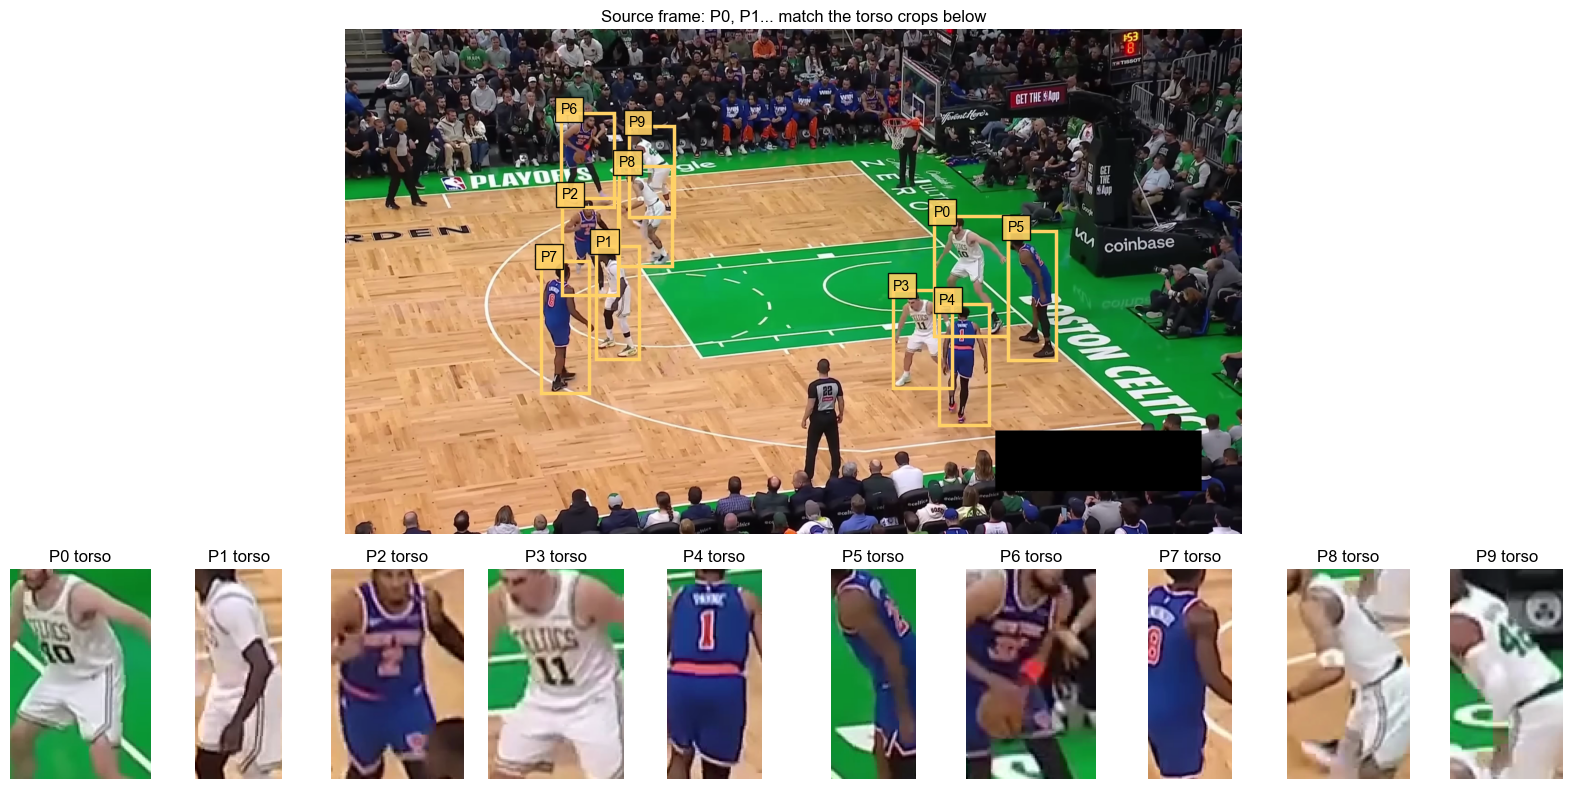

In [4]:
# Compare original box indices with torso crop indices side by side.
fig = plt.figure(figsize=(16, 8))
grid = fig.add_gridspec(2, max(3, len(crops)), height_ratios=[2.4, 1])
ax_main = fig.add_subplot(grid[0, :])
ax_main.imshow(frame)
ax_main.set_title("Source frame: P0, P1... match the torso crops below")
ax_main.axis("off")
for local_index, player in enumerate(valid_players):
    x1, y1, x2, y2 = player.bbox_xyxy
    ax_main.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor="#FFD166", linewidth=2.5))
    ax_main.text(x1, y1, f"P{local_index}", color="black", weight="bold",
                 bbox={"facecolor": "#FFD166", "alpha": 0.9})

for index, crop in enumerate(crops):
    ax = fig.add_subplot(grid[1, index])
    ax.imshow(crop)
    ax.set_title(f"P{index} torso")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Step 3 | Encode Different-Sized Crops as Fixed-Length Features

Count hue/saturation combinations in HSV space to obtain a two-dimensional histogram. Flatten it into a vector and apply $L_2$ normalization:

$$
\hat{\mathbf{h}}=\frac{\mathbf{h}}{\lVert\mathbf{h}\rVert_2+\epsilon}.
$$

Every crop then has the same feature length regardless of image size. Normalization reduces the effect of crop size on total counts.


In [5]:
# Encode each RGB crop as a normalized HSV(H,S) histogram.
def color_hist_embedding(crop_rgb, hue_bins=12, saturation_bins=8):
    '''Return a normalized 2D H/S histogram as one flat feature vector.'''
    hsv = cv2.cvtColor(np.ascontiguousarray(crop_rgb), cv2.COLOR_RGB2HSV)
    histogram = cv2.calcHist(
        [hsv], [0, 1], None,
        [hue_bins, saturation_bins],
        [0, 180, 0, 256],
    ).flatten().astype(np.float32)
    norm = float(np.linalg.norm(histogram))
    return histogram / max(norm, 1e-12)

features = np.vstack([color_hist_embedding(crop) for crop in crops])
print("number of crops:", len(crops))
print("feature matrix shape:", features.shape)
print("Each row is one player's crop; each column is an H/S color bin.")


number of crops: 10
feature matrix shape: (10, 96)
Each row is one player's crop; each column is an H/S color bin.


## Step 4 | Alternate Assignment and Update in Two-Cluster K-Means

Assign crop feature $\mathbf{x}_i$ to its nearest center:

$$
c_i=\arg\min_{k\in\{0,1\}}\lVert\mathbf{x}_i-\boldsymbol{\mu}_k\rVert_2^2.
$$

Update $\boldsymbol{\mu}_k$ using the mean of features in cluster $k$. Repeat until assignments stop changing or the iteration limit is reached. Labels `0/1` do not identify actual teams, so use Team A/B.


In [6]:
# Implement two-cluster K-means in NumPy with inspectable steps.
def kmeans_two_clusters(feature_matrix, max_iterations=50):
    if len(feature_matrix) < 2:
        raise ValueError("K-means requires at least two observations.")

    # Start at P0 and the point farthest from P0 to separate the initial centers.
    first_center_index = 0
    distances_from_first = np.linalg.norm(
        feature_matrix - feature_matrix[first_center_index], axis=1
    )
    second_center_index = int(np.argmax(distances_from_first))
    centers = feature_matrix[[first_center_index, second_center_index]].copy()
    labels = np.full(len(feature_matrix), -1, dtype=int)

    iterations_run = 0
    for iteration in range(max_iterations):
        iterations_run = iteration + 1
        # distances[i, k]: distance from player i to cluster center k.
        distances = np.linalg.norm(
            feature_matrix[:, None, :] - centers[None, :, :], axis=2
        )
        new_labels = distances.argmin(axis=1)
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # Update each center to its cluster mean; retain the center if the cluster is empty.
        for cluster_id in (0, 1):
            members = feature_matrix[labels == cluster_id]
            if len(members) > 0:
                centers[cluster_id] = members.mean(axis=0)
    return labels, centers, iterations_run

team_labels, cluster_centers, iterations = kmeans_two_clusters(features)
print("iterations:", iterations)
print("Team A members:", np.where(team_labels == 0)[0].tolist())
print("Team B members:", np.where(team_labels == 1)[0].tolist())


iterations: 3
Team A members: [0, 1, 3, 5, 8, 9]
Team B members: [2, 4, 6, 7]


## Step 5 | Reduce Features to 2D for Visualization

HSV histograms are high-dimensional. Center the features and apply SVD, the core operation of PCA, to show two directions. **K-means uses the original full features; the 2D coordinates are only for display.**


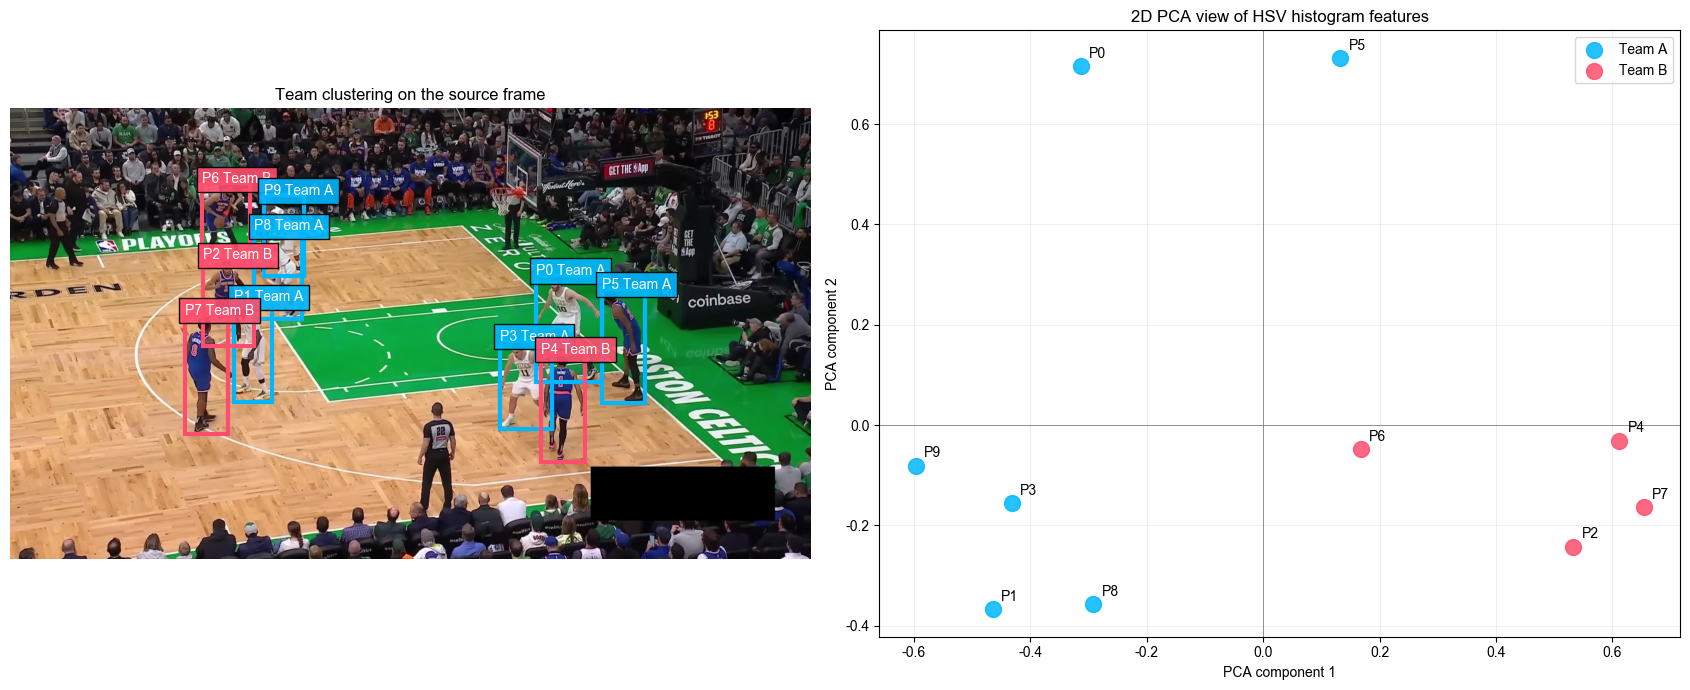

saved image: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d3_03_team_clustering.png
saved data: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d3_03_team_clustering.json


In [7]:
# Show crops, 2D features and team assignments on the source image together.
centered_features = features - features.mean(axis=0, keepdims=True)
_, _, vh = np.linalg.svd(centered_features, full_matrices=False)
component_count = min(2, vh.shape[0])
feature_2d = centered_features @ vh[:component_count].T
if component_count == 1:
    feature_2d = np.column_stack([feature_2d[:, 0], np.zeros(len(feature_2d))])

team_colors = {0: "#00B7FF", 1: "#FF4D6D"}
team_names = {0: "Team A", 1: "Team B"}
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Left: draw cluster labels on actual boxes and check their correspondence.
axes[0].imshow(frame)
axes[0].set_title("Team clustering on the source frame")
axes[0].axis("off")
result_rows = []
for index, (player, cluster_id) in enumerate(zip(valid_players, team_labels)):
    x1, y1, x2, y2 = player.bbox_xyxy
    color = team_colors[int(cluster_id)]
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=color, linewidth=3))
    axes[0].text(x1, y1, f"P{index} {team_names[int(cluster_id)]}",
                 color="white", weight="bold",
                 bbox={"facecolor": color, "alpha": 0.9})
    result_rows.append({
        "frame": FRAME_INDEX,
        "player_index": index,
        "source_detection_index": source_indices[index],
        "team_cluster": int(cluster_id),
        "team_name": team_names[int(cluster_id)],
        "bbox_xyxy": [float(value) for value in player.bbox_xyxy],
    })

# Right: each point is a torso crop; nearby points have similar HSV distributions.
for cluster_id in (0, 1):
    mask = team_labels == cluster_id
    axes[1].scatter(feature_2d[mask, 0], feature_2d[mask, 1], s=130,
                    color=team_colors[cluster_id], label=team_names[cluster_id], alpha=0.85)
for index, (x, y) in enumerate(feature_2d):
    axes[1].annotate(f"P{index}", (x, y), xytext=(6, 6), textcoords="offset points")
axes[1].axhline(0, color="gray", linewidth=0.6)
axes[1].axvline(0, color="gray", linewidth=0.6)
axes[1].set_title("2D PCA view of HSV histogram features")
axes[1].set_xlabel("PCA component 1")
axes[1].set_ylabel("PCA component 2")
axes[1].legend()
axes[1].grid(alpha=0.2)

OUTPUT_IMAGE.parent.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
fig.savefig(OUTPUT_IMAGE, dpi=160, bbox_inches="tight")
plt.show()
save_json(result_rows, OUTPUT_JSON)
print("saved image:", OUTPUT_IMAGE)
print("saved data:", OUTPUT_JSON)


## Interpret the Results and Limitations

Check more than whether two colors appear:

1. **Are the boxes correct?** Clustering cannot repair boxes around referees or spectators.
2. **Do the crops contain jerseys?** Floor, skin and shadows contaminate color features.
3. **Are same-team points near each other in 2D?** Overlap may reflect lighting, similar jerseys or PCA compression.
4. **Do Team A/B labels look reasonable on the image?** Cluster numbers are not team names or jersey recognition.

### Extensions for a Full Project

- Collect crops across frames and assign teams by majority vote within each `track_id`.
- Exclude referees or introduce a third referee cluster.
- Replace color histograms with pretrained image embeddings.
- Combine team and jersey-number/OCR outputs to identify players.

## Outputs

- `assets/results/d3_03_team_clustering.png`: image assignments and feature scatter plot.
- `assets/results/d3_03_team_clustering.json`: Team A/B assignments for each player box.
